# Uber Rides - Exploratory Data Analysis

## Research Objective
The main objective of this analysis is to identify the most profitable driving hours, days, and conditions for Uber drivers in Dubrovnik, Croatia.

Using historical Uber ride data from 2024 and 2025, combined with weather conditions and cruise ship arrivals, this analysis aims to answer the following questions:
1. Which hours and days generate the highest ride frequency and earnings?
2. When are higher-value and more profitable trips most frequently recorded?
3. How do trip fares, distances, and durations affect earning potential?
4. How do rainfall and cruise ship arrivals relate to ride demand and earnings?
5. Which combinations of time and external conditions provide the best opportunities to maximize earnings?

### Analytical Approach
The analysis focuses on ride frequency, fare values, trip duration, and earning efficiency to identify the most financially rewarding driving patterns.
The goal is to develop data-driven recommendations for optimizing driving schedules and maximizing earning potential.

### Data Scope and Limitations

This analysis focuses exclusively on trips completed through the Uber platform during the 2024 and 2025 tourist seasons in Dubrovnik, Croatia.

The recorded fare values represent Uber trip fares, not the driver’s total or net earnings. Trips completed through other platforms, such as Bolt, and private transportation services outside the Uber application are not included in the dataset.

Therefore, the findings are intended to identify patterns in Uber ride activity, fare values, and earning opportunities rather than measure the driver’s overall income across all transportation services.

Profitability is evaluated based on recorded Uber fares and trip-related time, without deducting platform commissions or operating expenses.

## Dataset overview

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../../data/processed_data/uber_analysis_ready.csv')
df.head()

,ride_category,request_time,start_time,end_time,trip_distance_km,trip_duration_minutes,base_fare,original_fare,hour_of_day,day_of_week,month,is_weekend,year,start_time_local,ride_hour,precipitation,is_raining,ride_date,cruises_daily,cruises_hourly
0,UberX,2024-04-19 13:04:18+00:00,2024-04-19 13:06:29+00:00,2024-04-19 13:21:28+00:00,4.39,14.98,1.43,5.34,13,Friday,April,False,2024,2024-04-19 13:06:29,2024-04-19 13:00:00,0.0,False,2024-04-19,0,0
1,UberX,2024-04-19 14:40:02+00:00,2024-04-19 14:47:35+00:00,2024-04-19 14:55:15+00:00,2.93,7.67,1.43,4.11,14,Friday,April,False,2024,2024-04-19 14:47:35,2024-04-19 14:00:00,0.0,False,2024-04-19,0,0
2,UberX,2024-05-01 12:40:49+00:00,2024-05-01 12:47:15+00:00,2024-05-01 13:05:28+00:00,2.55,18.10,1.43,4.00,12,Wednesday,May,False,2024,2024-05-01 12:47:15,2024-05-01 12:00:00,0.0,False,2024-05-01,2,0
3,UberX,2024-05-01 13:02:55+00:00,2024-05-01 13:12:16+00:00,2024-05-01 13:25:53+00:00,8.32,13.62,1.43,8.12,13,Wednesday,May,False,2024,2024-05-01 13:12:16,2024-05-01 13:00:00,0.4,True,2024-05-01,2,0
4,UberX,2024-05-01 13:21:49+00:00,2024-05-01 13:40:32+00:00,2024-05-01 13:55:00+00:00,5.34,14.47,1.43,5.67,13,Wednesday,May,False,2024,2024-05-01 13:40:32,2024-05-01 13:00:00,0.4,True,2024-05-01,2,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1334 entries, 0 to 1333
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ride_category          1334 non-null   object 
 1   request_time           1334 non-null   object 
 2   start_time             1334 non-null   object 
 3   end_time               1334 non-null   object 
 4   trip_distance_km       1334 non-null   float64
 5   trip_duration_minutes  1334 non-null   float64
 6   base_fare              1334 non-null   float64
 7   original_fare          1334 non-null   float64
 8   hour_of_day            1334 non-null   int64  
 9   day_of_week            1334 non-null   object 
 10  month                  1334 non-null   object 
 11  is_weekend             1334 non-null   bool   
 12  year                   1334 non-null   int64  
 13  start_time_local       1334 non-null   object 
 14  ride_hour              1334 non-null   object 
 15  prec

In [4]:
date_columns = ['start_time_local', 'ride_hour','ride_date']

for col in date_columns:
    df[col]= pd.to_datetime(df[col])
df[date_columns].dtypes

start_time_local    datetime64[ns]
ride_hour           datetime64[ns]
ride_date           datetime64[ns]
dtype: object

## Ride and Earnings Overview
Analyzing ride characteristics, fare distributions, and difference in trip performance between 2024 and 2025.

In [5]:
df[[
    'base_fare',
    'original_fare',
    'trip_distance_km',
    'trip_duration_minutes'
]].describe().round(2)

,base_fare,original_fare,trip_distance_km,trip_duration_minutes
count,1334.00,1334.00,1334.00,1334.00
mean,1.99,14.07,8.34,16.63
std,1.78,8.40,6.96,9.51
min,1.43,4.00,0.00,2.42
25%,1.48,8.46,3.57,9.74
50%,1.79,10.50,5.34,14.40
75%,1.79,17.55,11.49,21.52
max,14.50,72.38,52.09,81.82


In [6]:
df['original_fare'].sum().round(2)

np.float64(18764.18)

In [7]:
df.groupby('year')['original_fare'].agg(
    ['count','sum', 'mean']
).round(2)

,count,sum,mean
year,,,
2024,822,10873.26,13.23
2025,512,7890.92,15.41


In [8]:
df.groupby('ride_category')['original_fare'].agg(
    ['count', 'mean', 'sum']
).round(2)

,count,mean,sum
ride_category,,,
Black,4,27.90,111.59
Mid-Tier,14,19.68,275.45
UberX,1316,13.96,18377.14


In [9]:
df[df['ride_category'] == 'UberX'].groupby('year')['original_fare'].mean().round(2)

year
2024    13.23
2025    15.19
Name: original_fare, dtype: float64

In [10]:
df[df['ride_category'] == 'UberX'].groupby('year')[
    ['trip_distance_km','trip_duration_minutes','original_fare']
    ].mean().round(2)

,trip_distance_km,trip_duration_minutes,original_fare
year,,,
2024,8.02,16.42,13.23
2025,8.88,17.00,15.19


In [13]:
same_period = df[
    (df['ride_category'] == 'UberX') &
    (df['start_time_local'].dt.strftime('%m-%d').between('07-11', '08-29'))
    ]
same_period.groupby('year').agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare', 'mean'),
    avg_distance=('trip_distance_km', 'mean'),
    avg_duration=('trip_duration_minutes','mean')
).round(2)

,rides,avg_fare,avg_distance,avg_duration
year,,,,
2024,460,14.49,8.62,17.36
2025,494,15.19,8.88,17.00


## Ride and Earnings - Key Findings

* Dataset overview: The analysis includes 1,334 completed Uber rides, with total recorded original fares of EUR 18,764.18. UberX accounted for approximately 98.7% of all rides.

* Seasonality matters: The initial year-over-year comparison showed a 14.8% increase in average UberX fares. However, when comparing the same period (July 11 – August 29), the increase was only 4.8%, highlighting the importance of accounting for seasonal differences.

* Trip characteristics: During the comparable periods, average trip distance increased from 8.62 km to 8.88 km, while average duration decreased slightly from 17.36 to 17.00 minutes. These changes may partially explain the increase in average fares.

* Pricing observations: Despite an approximately 17% reduction in the base fare between the peak seasons of 2024 and 2025, average UberX trip fares increased. This suggests that base fare changes alone do not explain overall trip pricing.

* Limitations: The dataset represents completed rides from a single driver. Original fares do not reflect net earnings, and differences between years may be influenced by trip characteristics, seasonal conditions, and other factors.

## Time-Based Analysis
Analyzing ride patterns and fare performance across different hours and days of the week.

In [15]:
hourly_analysis = df.groupby('hour_of_day').agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare','mean')
).round(2)
hourly_analysis

,rides,avg_fare
hour_of_day,,
0,18,13.23
1,13,15.13
2,12,18.61
3,8,25.94
4,11,26.73
5,8,28.30
6,9,23.22
7,13,21.77
8,23,18.25


In [17]:
hourly_analysis = hourly_analysis.reset_index()

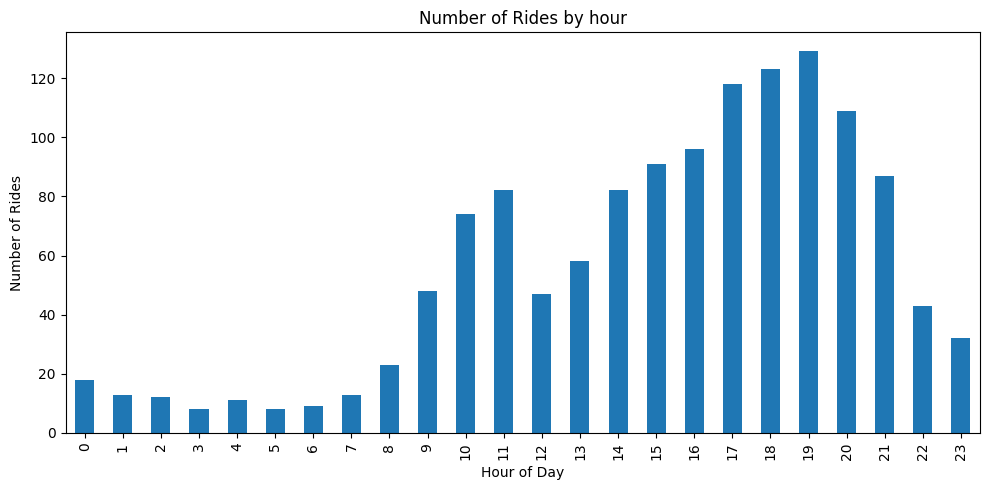

In [18]:
hourly_analysis.plot(
    x='hour_of_day',
    y='rides',
    kind='bar',
    figsize=(10, 5),
    legend=False
)
plt.title('Number of Rides by hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Rides')
plt.tight_layout()
plt.show()

##### Figure 1: Number of Rides by Hour

The chart shows the total number of completed Uber rides grouped by their starting hour across the 2024 and 2025 datasets, rather than rides recorded on a single day.
The highest number of recorded rides ocurred during the evening hours, peaking around 19:00.

Note: This chart reflects the driver's recorded activity, not overall market demand, since working hours were not tracked.

In [19]:
daily_analysis = df.groupby('day_of_week').agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare','mean')
).round(2)
daily_analysis

,rides,avg_fare
day_of_week,,
Friday,274,13.26
Monday,196,15.31
Saturday,181,14.78
Sunday,141,14.65
Thursday,205,13.18
Tuesday,166,15.57
Wednesday,171,12.28


In [20]:
days_order = [
    'Monday',  'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday']
daily_analysis = daily_analysis.reindex(days_order)
daily_analysis

,rides,avg_fare
day_of_week,,
Monday,196,15.31
Tuesday,166,15.57
Wednesday,171,12.28
Thursday,205,13.18
Friday,274,13.26
Saturday,181,14.78
Sunday,141,14.65


In [22]:
daily_analysis['active_days'] = df.groupby('day_of_week')['ride_date'].nunique()
daily_analysis['rides_per_active_day'] = (
    daily_analysis['rides'] / daily_analysis['active_days']
).round(2)
daily_analysis

,rides,avg_fare,active_days,rides_per_active_day
day_of_week,,,,
Monday,196,15.31,20,9.80
Tuesday,166,15.57,19,8.74
Wednesday,171,12.28,19,9.00
Thursday,205,13.18,17,12.06
Friday,274,13.26,23,11.91
Saturday,181,14.78,18,10.06
Sunday,141,14.65,13,10.85


In [25]:
daily_analysis['fare_per_active_day'] = (
    df.groupby('day_of_week')['original_fare'].sum()
    / daily_analysis['active_days']
).round(2)
daily_analysis

,rides,avg_fare,active_days,rides_per_active_day,fare_per_active_day
day_of_week,,,,,
Monday,196,15.31,20,9.80,150.07
Tuesday,166,15.57,19,8.74,136.06
Wednesday,171,12.28,19,9.00,110.55
Thursday,205,13.18,17,12.06,158.95
Friday,274,13.26,23,11.91,158.03
Saturday,181,14.78,18,10.06,148.64
Sunday,141,14.65,13,10.85,158.84


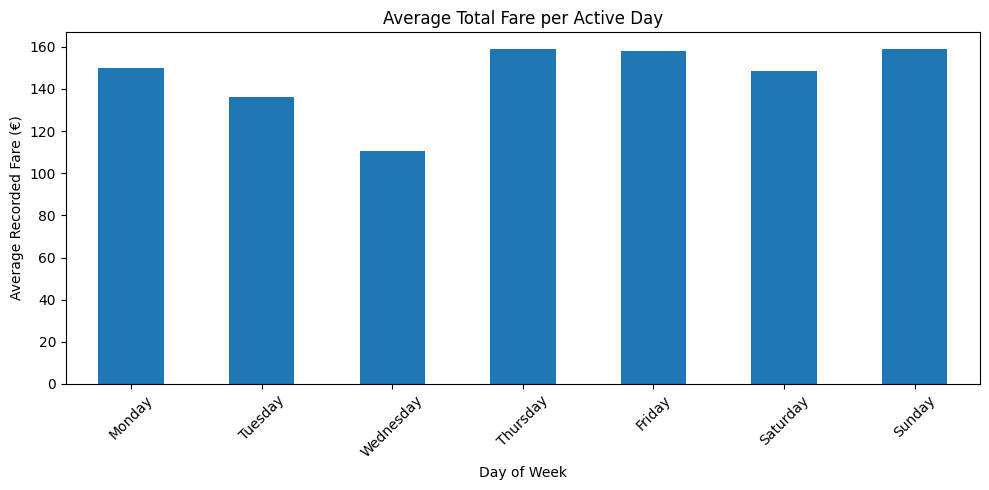

In [26]:
daily_analysis['fare_per_active_day'].plot(
    kind='bar',
    figsize=(10, 5)
)
plt.title('Average Total Fare per Active Day')
plt.xlabel('Day of Week')
plt.ylabel('Average Recorded Fare (€)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Figure 2: Average Total Fare per Active Day of the Week

The chart shows the average total recorded fare per active driving day, grouped by day of the week across the 2024 and 2025 datasets.

Thursday recorded the highest average (€158.95), closely followed by Sunday (€158.95) and Friday (€158.03).
Wednesday showed the lowest average (€110.55).

These findings suggest that the highest total ride count does not necessarily correspond to the highest average fare total per active day.

## Time-Based Analysis - Key Findings

The analysis of Uber rides from 2024 and 2025 revealed several patterns in ride activity and earning potential.

* Hourly patterns: The highest number of recorded rides occurred during the evening hours, peaking around 19:00.
* Ride frequency: Friday recorded the highest total number of rides (274), while Sunday had the lowest (141).
* Rides per active day: Thursday had the highest average number of completed rides per active day (12.06), closely followed by Friday (11.91).
* Earning potential: Thursday generated the highest average recorded fare total per active day (€158.95), followed closely by Sunday (€158.84) and Friday (€158.03).
* Lowest performance: Wednesday recorded the lowest average fare total per active day (€110.55).

#### Conclusion:

The findings suggest that evening hours and certain days of the week may offer more favorable earning opportunities. However, the day with the highest total number of rides does not necessarily generate the highest average fare total per active day.

These patterns provide an initial foundation for identifying profitable driving periods. Further analysis of weather conditions and cruise ship arrivals will help investigate how external factors relate to these opportunities.


## Weather Impact Analysis 
Investigating how rainfall is associated with Uber ride frequency, fare values, and trip duration.

In [27]:
weather_analysis = df.groupby('is_raining').agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare', 'mean'),
    avg_duration=('trip_duration_minutes', 'mean')
).round(2)

weather_analysis

,rides,avg_fare,avg_duration
is_raining,,,
False,1234,14.15,16.60
True,100,12.99,17.11


In [28]:
weather_analysis['fare_per_trip_hour'] = (
    df.groupby('is_raining')['original_fare'].sum()
    / df.groupby('is_raining')['trip_duration_minutes'].sum() * 60
).round(2)

weather_analysis

,rides,avg_fare,avg_duration,fare_per_trip_hour
is_raining,,,,
False,1234,14.15,16.60,51.17
True,100,12.99,17.11,45.55


In [30]:
df['request_time'] = pd.to_datetime(df['request_time'])
df['start_time'] = pd.to_datetime(df['start_time'])

df['request_to_pickup_min'] = (
    df['start_time'] - df['request_time']
).dt.total_seconds() / 60
df.groupby('is_raining')['request_to_pickup_min'].agg(
    ['count','mean','median']
).round(2)

,count,mean,median
is_raining,,,
False,1234,7.71,6.61
True,100,7.99,6.55


### Pickup Timing Analysis

The average time between ride request and trip start was 7.71 minutes during dry conditions and 7.99 minutes during rainfall.

Median values were nearly identical (6.61 and 6.55 minutes, respectively), suggesting no substantial difference in request-to-trip-start times between the two weather conditions.

These findings do not provide strong evidence that rainfall increased pickup-related delays in the recorded Uber trips.

## Weather analysis - Preliminary findings
Uber-recorded trips during dry conditions had a higher average fare (€14.15) than trips recorded during rainfall (€12.99).

Fare per hour of completed trip duration was also higher in dry conditions (€51.17) compared with rainy conditions (€45.55).

However, the dataset includes only trips recorded through the Uber platform. Additional trips completed outside the application are not represented, potentially affecting comparisons between weather conditions.

Therefore, these results do not establish whether rainy or dry conditions offer better overall earning opportunities.

## Cruise Ship Impact Analysis
Investigating how cruise ship arrivals are associated with Uber ride frequency, fare values, and earning opportunities.

In [29]:
cruise_analysis = df.groupby(df['cruises_daily'] > 0).agg(
    rides=('original_fare','count'),
    avg_fare=('original_fare', 'mean'),
    avg_duration=('trip_duration_minutes', 'mean')
).round(2)

cruise_analysis

,rides,avg_fare,avg_duration
cruises_daily,,,
False,95,12.54,15.10
True,1239,14.18,16.75


In [31]:
cruise_count_analysis = df.groupby('cruises_daily').agg(
    rides=('original_fare', 'count'),
    active_days=('ride_date', 'nunique'),
    avg_fare=('original_fare', 'mean')
).round(2)

cruise_count_analysis

,rides,active_days,avg_fare
cruises_daily,,,
0,95,9,12.54
1,239,25,15.18
2,449,45,14.87
3,373,35,13.77
4,130,11,11.63
5,48,4,12.92


In [33]:
cruise_count_analysis['rides_per_active_day'] = (
    cruise_count_analysis['rides']
    / cruise_count_analysis['active_days']
).round(2)

cruise_count_analysis['fare_per_active_day'] = (
    df.groupby('cruises_daily')['original_fare'].sum()
    / cruise_count_analysis['active_days']
).round(2)

cruise_count_analysis

,rides,active_days,avg_fare,rides_per_active_day,fare_per_active_day
cruises_daily,,,,,
0,95,9,12.54,10.56,132.38
1,239,25,15.18,9.56,145.12
2,449,45,14.87,9.98,148.40
3,373,35,13.77,10.66,146.72
4,130,11,11.63,11.82,137.39
5,48,4,12.92,12.00,155.03


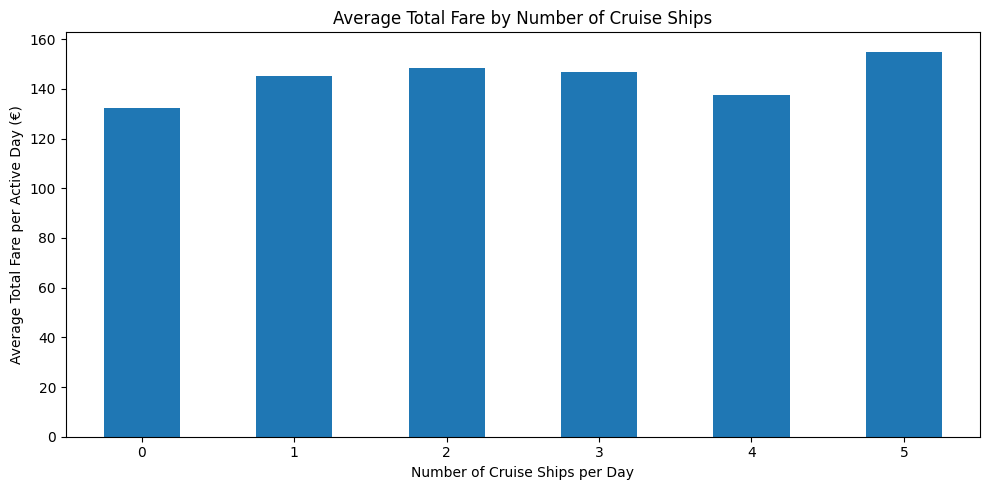

In [34]:
cruise_count_analysis['fare_per_active_day'].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Average Total Fare by Number of Cruise Ships')
plt.xlabel('Number of Cruise Ships per Day')
plt.ylabel('Average Total Fare per Active Day (€)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Figure 3: Average Total Fare by Number of Cruise Ships

The chart illustrates the average total recorded fare per active driving day, grouped by the number of cruise ships arriving in Dubrovnik.

The highest average was recorded on days with five cruise ships, while days without cruise ship arrivals showed the lowest average.

However, the relationship is not consistent across all groups. The five-cruise-ship category contains only four active driving days, limiting the reliability of this comparison.

These findings suggest a possible association between cruise ship activity and earning opportunities, but do not establish a direct causal relationship.

In [35]:
cruise_hourly_analysis = df.groupby('cruises_hourly').agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare', 'mean'),
    avg_duration=('trip_duration_minutes', 'mean')
).round(2)

cruise_hourly_analysis

,rides,avg_fare,avg_duration
cruises_hourly,,,
0,1280,13.99,16.64
1,51,16.12,16.77
2,3,10.56,13.75


In [36]:
df.groupby([
    'hour_of_day',
    df['cruises_hourly'] > 0
])['original_fare'].agg(
    ['count', 'mean']
).round(2)

count   mean
hour_of_day cruises_hourly              
0           False              18  13.23
1           False              13  15.13
2           False              12  18.61
3           False               8  25.94
4           False              11  26.73
5           False               7  30.54
            True                1  12.67
6           False               8  22.62
            True                1  28.00
7           False               7  26.75
            True                6  15.95
8           False              18  19.29
            True                5  14.52
9           False              47  16.99
            True                1  12.18
10          False              72  18.30
            True                2  28.00
11          False              81  15.10
            True                1  21.90
12          False              43  13.97
            True                4  17.74
13          False              57  12.98
            True                1   8.09
14          False              76  12.31
            True                6  18.12
15          False              89  14.19
            True                2  17.56
16          False              91  11.98
            True                5   9.40
17          False             118  12.72
18          False             123  12.53
19          False             127  12.73
            True                2  19.98
20          False              95  12.54
            True               14  13.15
21          False              86  12.66
            True                1  17.66
22          False              43  12.23
23          False              30  12.96
            True                2  21.64

In [37]:
cruise_hours = pd.read_csv(
    '../../data/processed_data/cruise_hourly_cleaned.csv'
)

cruise_hours.head()

,arrival_datetime,cruise_count_hourly,cruise_count_daily
0,2024-04-22 20:00:00,1,1
1,2024-04-23 07:00:00,1,1
2,2024-04-24 06:00:00,1,3
3,2024-04-24 07:00:00,2,3
4,2024-04-25 08:00:00,1,1


In [38]:
cruise_hours['arrival_datetime'] = pd.to_datetime(
    cruise_hours['arrival_datetime']
)

arrivals = cruise_hours.groupby(
    'arrival_datetime'
)['cruise_count_hourly'].sum()

df['cruises_previous_3h'] = sum(
    (df['ride_hour'] - pd.Timedelta(hours=h))
    .map(arrivals).fillna(0)
    for h in [1, 2, 3]
).astype(int)

df.groupby(df['cruises_previous_3h'] > 0).agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare', 'mean'),
    avg_duration=('trip_duration_minutes', 'mean')
).round(2)

,rides,avg_fare,avg_duration
cruises_previous_3h,,,
False,1107,13.81,16.18
True,227,15.33,18.83


In [39]:
cruise_efficiency = df.groupby(
    df['cruises_previous_3h'] > 0
).agg(
    total_fare=('original_fare', 'sum'),
    total_minutes=('trip_duration_minutes', 'sum')
)

cruise_efficiency['fare_per_trip_hour'] = (
    cruise_efficiency['total_fare']
    / cruise_efficiency['total_minutes'] * 60
).round(2)

cruise_efficiency

,total_fare,total_minutes,fare_per_trip_hour
cruises_previous_3h,,,
False,15283.23,17916.00,51.18
True,3480.95,4274.38,48.86


In [40]:
cruise_hour_comparison = df.groupby([
    'hour_of_day',
    df['cruises_previous_3h'] > 0
]).agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare', 'mean'),
    avg_duration=('trip_duration_minutes', 'mean')
).round(2)

cruise_hour_comparison

rides  avg_fare  avg_duration
hour_of_day cruises_previous_3h                               
0           False                   17     12.95         11.97
            True                     1     18.02         21.97
1           False                   13     15.13         14.42
2           False                   12     18.61         14.79
3           False                    8     25.94         20.57
4           False                   11     26.73         22.58
5           False                    8     28.30         23.54
6           False                    8     25.21         21.23
            True                     1      7.29         10.12
7           False                    8     25.16         23.26
            True                     5     16.33         14.19
8           False                    8     18.28         16.47
            True                    15     18.24         20.09
9           False                   11     19.35         21.18
            True                    37     16.17         18.68
10          False                   28     15.96         20.65
            True                    46     20.15         26.62
11          False                   55     16.44         20.40
            True                    27     12.61         18.13
12          False                   41     15.21         18.81
            True                     6      8.00         11.52
13          False                   53     12.50         15.77
            True                     5     17.05         19.26
14          False                   70     13.11         15.82
            True                    12     10.57         16.11
15          False                   78     14.00         18.52
            True                    13     15.89         19.35
16          False                   83     12.28         14.76
            True                    13      9.05         11.10
17          False                  110     12.58         15.14
            True                     8     14.71         16.50
18          False                  117     12.58         15.17
            True                     6     11.53         12.83
19          False                  120     12.61         15.45
            True                     9     15.88         18.53
20          False                  105     12.70         15.36
            True                     4     10.34         13.05
21          False                   79     12.60         15.27
            True                     8     13.79         13.73
22          False                   37     12.09         12.93
            True                     6     13.11         16.12
23          False                   27     12.64         13.00
            True                     5     18.15         15.12

In [41]:
cruise_hour_comparison['fare_per_trip_hour'] = (
    cruise_hour_comparison['avg_fare']
    / cruise_hour_comparison['avg_duration'] * 60
).round(2)

cruise_hour_comparison.loc[8:16]

rides  avg_fare  avg_duration  \
hour_of_day cruises_previous_3h                                  
8           False                    8     18.28         16.47   
            True                    15     18.24         20.09   
9           False                   11     19.35         21.18   
            True                    37     16.17         18.68   
10          False                   28     15.96         20.65   
            True                    46     20.15         26.62   
11          False                   55     16.44         20.40   
            True                    27     12.61         18.13   
12          False                   41     15.21         18.81   
            True                     6      8.00         11.52   
13          False                   53     12.50         15.77   
            True                     5     17.05         19.26   
14          False                   70     13.11         15.82   
            True                    12     10.57         16.11   
15          False                   78     14.00         18.52   
            True                    13     15.89         19.35   
16          False                   83     12.28         14.76   
            True                    13      9.05         11.10   

                                 fare_per_trip_hour  
hour_of_day cruises_previous_3h                      
8           False                             66.59  
            True                              54.47  
9           False                             54.82  
            True                              51.94  
10          False                             46.37  
            True                              45.42  
11          False                             48.35  
            True                              41.73  
12          False                             48.52  
            True                              41.67  
13          False                             47.56  
            True                              53.12  
14          False                             49.72  
            True                              39.37  
15          False                             45.36  
            True                              49.27  
16          False                             49.92  
            True                              48.92

In [42]:
df['total_trip_time'] = (
    df['request_to_pickup_min']
    + df['trip_duration_minutes']
)

cruise_time_efficiency = df.groupby([
    'hour_of_day',
    df['cruises_previous_3h'] > 0
]).agg(
    rides=('original_fare', 'count'),
    total_fare=('original_fare', 'sum'),
    total_minutes=('total_trip_time', 'sum')
)

cruise_time_efficiency['fare_per_hour'] = (
    cruise_time_efficiency['total_fare']
    / cruise_time_efficiency['total_minutes'] * 60
).round(2)

cruise_time_efficiency.loc[8:16, ['rides', 'fare_per_hour']]

rides  fare_per_hour
hour_of_day cruises_previous_3h                      
8           False                    8          42.97
            True                    15          41.64
9           False                   11          43.00
            True                    37          38.01
10          False                   28          32.63
            True                    46          33.36
11          False                   55          33.98
            True                    27          28.80
12          False                   41          36.37
            True                     6          24.27
13          False                   53          31.51
            True                     5          35.51
14          False                   70          31.85
            True                    12          27.96
15          False                   78          30.90
            True                    13          36.89
16          False                   83          33.19
            True                    13          33.64

In [43]:
cruise_year_analysis = df.groupby([
    'year',
    df['cruises_previous_3h'] > 0
]).agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare', 'mean'),
    total_fare=('original_fare', 'sum'),
    total_time=('total_trip_time', 'sum')
)

cruise_year_analysis['fare_per_hour'] = (
    cruise_year_analysis['total_fare']
    / cruise_year_analysis['total_time'] * 60
)

cruise_year_analysis.round(2)

rides  avg_fare  total_fare  total_time  \
year cruises_previous_3h                                            
2024 False                  673     12.98     8736.63    15852.97   
     True                   149     14.34     2136.63     3825.79   
2025 False                  434     15.08     6546.60    10605.51   
     True                    78     17.23     1344.32     2217.51   

                          fare_per_hour  
year cruises_previous_3h                 
2024 False                        33.07  
     True                         33.51  
2025 False                        37.04  
     True                         36.37

## Cruise Ship Analysis - Key Findings

The analysis revealed several patterns in Uber ride activity and earning potential associated with cruise ship arrivals in Dubrovnik.

* Cruise ship activity: Trips recorded on days with cruise ship arrivals had a higher average fare (€14.18) compared with days without arrivals (€12.54).
* Number of cruise ships: The highest average total fare per active driving day (€155.03) occurred on days with five cruise ships. However, this category included only four active days, limiting the reliability of the result.
* Hourly arrivals: Trips recorded during hours with one cruise ship arrival had a higher average fare (€16.12) than trips recorded during hours without arrivals (€13.99).
* Delayed effects: Trips recorded 1–3 hours after cruise ship arrivals had an approximately 11% higher average fare (€15.33) compared with other periods (€13.81).
* Earning efficiency: Higher fares did not consistently translate into higher fare values per hour of trip-related time. Including the time between ride request and trip start reduced the apparent financial advantage of some periods.
* Yearly consistency: Higher average fares following cruise ship arrivals were observed in both 2024 and 2025, although earning efficiency showed mixed results.

#### Conclusion:

Cruise ship arrivals appear to be a potentially useful indicator of higher-value Uber ride opportunities, particularly during the hours following arrival.

However, the relationship between cruise activity and earning efficiency varies across different hours and years. These patterns are observational and may also reflect differences in seasonality, driving schedules, and trip characteristics.

Further analysis combining time of day, day of the week, weather conditions, and cruise ship activity will help identify the most promising driving periods for maximizing earnings.

## Combined Factors Analysis
Investigating how time, weather conditions, and cruise ship arrivals interact to identify the most favorable opportunities for Uber earnings.

In [44]:
df['recent_cruise_arrival'] = df['cruises_previous_3h'] > 0

combined_analysis = df.groupby([
    'is_raining',
    'recent_cruise_arrival'
]).agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare', 'mean'),
    total_fare=('original_fare', 'sum'),
    total_minutes=('total_trip_time', 'sum')
)

combined_analysis['fare_per_hour'] = (
    combined_analysis['total_fare']
    / combined_analysis['total_minutes'] * 60
)

combined_analysis[
    ['rides', 'avg_fare', 'fare_per_hour']
].round(2)

rides  avg_fare  fare_per_hour
is_raining recent_cruise_arrival                                
False      False                   1022     13.87          34.96
           True                     212     15.51          34.85
True       False                     85     13.01          31.20
           True                      15     12.86          30.24

In [45]:
time_combination = df.groupby([
    'day_of_week',
    'hour_of_day'
]).agg(
    rides=('original_fare', 'count'),
    avg_fare=('original_fare', 'mean'),
    total_fare=('original_fare', 'sum'),
    total_minutes=('total_trip_time', 'sum')
)

time_combination['fare_per_hour'] = (
    time_combination['total_fare']
    / time_combination['total_minutes'] * 60
)

time_combination[
    time_combination['rides'] >= 10
][['rides', 'avg_fare', 'fare_per_hour']].sort_values(
    'fare_per_hour', ascending=False
).head(15).round(2)

rides  avg_fare  fare_per_hour
day_of_week hour_of_day                                
Sunday      1               12     14.90          46.88
            2               11     18.65          46.69
Thursday    12              12     13.02          44.75
Sunday      0               14     11.65          39.55
Friday      22              12     13.06          38.97
Monday      18              22     14.47          38.49
Wednesday   21              10      9.93          38.37
Saturday    17              13     14.24          38.16
Monday      16              14     15.14          38.12
Tuesday     14              13     18.12          37.99
            17              13     16.98          37.89
Saturday    22              17     12.80          36.73
Thursday    21              11     16.11          36.53
Saturday    23              17     10.78          36.45
Tuesday     18              15     12.93          35.92

In [46]:
df['time_block'] = pd.cut(
    df['hour_of_day'],
    bins=[-1, 3, 7, 11, 15, 19, 23],
    labels=['00-03', '04-07', '08-11',
            '12-15', '16-19', '20-23']
)

block_analysis = df.groupby(
    ['day_of_week', 'time_block'],
    observed=True
).agg(
    rides=('original_fare', 'count'),
    active_days=('ride_date', 'nunique'),
    avg_fare=('original_fare', 'mean'),
    total_fare=('original_fare', 'sum')
)

block_analysis['fare_per_active_day'] = (
    block_analysis['total_fare']
    / block_analysis['active_days']
)

block_analysis[
    block_analysis['rides'] >= 20
][['rides', 'active_days', 'avg_fare',
   'fare_per_active_day']].sort_values(
    'fare_per_active_day',
    ascending=False
).head(12).round(2)

,,rides,active_days,avg_fare,fare_per_active_day
day_of_week,time_block,,,,
Sunday,00-03,43,7,16.13,99.11
Thursday,16-19,75,13,12.88,74.28
Saturday,16-19,50,10,14.23,71.16
Sunday,16-19,44,7,11.31,71.08
Tuesday,16-19,63,13,13.90,67.34
Saturday,20-23,66,12,12.07,66.36
Tuesday,12-15,49,13,16.93,63.83
Friday,20-23,77,16,13.22,63.60
Saturday,08-11,32,8,15.67,62.69


In [47]:
top_periods = df[
    ((df['day_of_week'] == 'Sunday') & (df['time_block'] == '00-03')) |
    ((df['day_of_week'] == 'Thursday') & (df['time_block'] == '16-19')) |
    ((df['day_of_week'] == 'Saturday') & (df['time_block'] == '16-19'))
]

year_check = top_periods.groupby(
    ['year', 'day_of_week', 'time_block'],
    observed=True
).agg(
    rides=('original_fare', 'count'),
    active_days=('ride_date', 'nunique'),
    total_fare=('original_fare', 'sum')
)

year_check['fare_per_active_day'] = (
    year_check['total_fare'] / year_check['active_days']
)

year_check.round(2)

rides  active_days  total_fare  \
year day_of_week time_block                                   
2024 Saturday    16-19          32            7      432.26   
     Sunday      00-03          32            5      513.69   
     Thursday    16-19          45            9      548.28   
2025 Saturday    16-19          18            3      279.30   
     Sunday      00-03          11            2      180.05   
     Thursday    16-19          30            4      417.40   

                             fare_per_active_day  
year day_of_week time_block                       
2024 Saturday    16-19                     61.75  
     Sunday      00-03                    102.74  
     Thursday    16-19                     60.92  
2025 Saturday    16-19                     93.10  
     Sunday      00-03                     90.02  
     Thursday    16-19                    104.35

In [48]:
period_conditions = top_periods.groupby(
    ['day_of_week', 'time_block'],
    observed=True
).agg(
    rides=('original_fare', 'count'),
    rainy_pct=('is_raining', lambda x: x.mean() * 100),
    after_cruise_pct=(
        'cruises_previous_3h',
        lambda x: (x > 0).mean() * 100
    )
).round(2)

period_conditions

,,rides,rainy_pct,after_cruise_pct
day_of_week,time_block,,,
Saturday,16-19,50,4.00,0.0
Sunday,00-03,43,0.00,0.0
Thursday,16-19,75,10.67,0.0


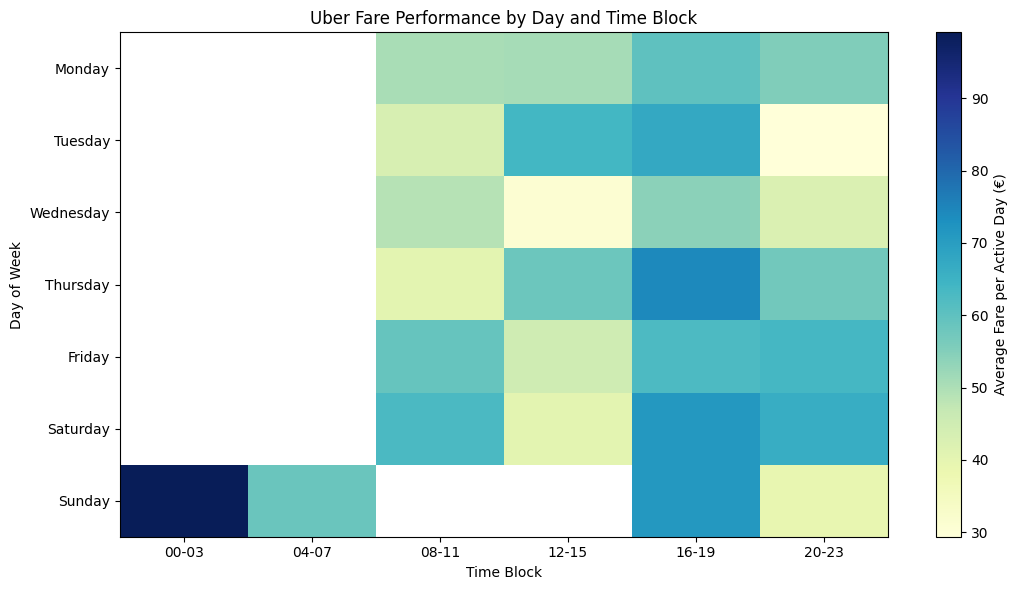

In [49]:
heatmap_data = (
    block_analysis['fare_per_active_day']
    .where(block_analysis['active_days'] >= 5)
    .unstack('time_block')
    .reindex(days_order)
)

plt.figure(figsize=(11, 6))

plt.imshow(heatmap_data, aspect='auto', cmap='YlGnBu')

plt.xticks(range(len(heatmap_data.columns)),
           heatmap_data.columns)
plt.yticks(range(len(heatmap_data.index)),
           heatmap_data.index)

plt.colorbar(label='Average Fare per Active Day (€)')

plt.title('Uber Fare Performance by Day and Time Block')
plt.xlabel('Time Block')
plt.ylabel('Day of Week')

plt.tight_layout()
plt.show()

##### Figure 4: Uber Fare Performance by Day and Time Block

The heatmap illustrates the average total recorded fare per active driving day across different days of the week and four-hour time blocks during the 2024 and 2025 seasons.

Sunday between 00:00 and 03:59 recorded the highest average (€99.11), followed by Thursday between 16:00 and 19:59 (€74.28).

The 16:00–19:59 period also showed relatively strong performance across several weekdays, suggesting that late afternoon and early evening may offer promising earning opportunities.

Only combinations with at least five active driving days are displayed. Missing values indicate insufficient observations rather than zero earnings.

These results reflect recorded fares within each time block and do not represent earnings from four hours of continuous driving.

## Key Findings – Combined Factors Analysis

The combined analysis of driving periods, weather conditions, and cruise ship arrivals revealed several patterns in Uber earning opportunities.

* Most promising time blocks: Sunday between 00:00 and 03:59 recorded the highest average fare total per active day (€99.11), although this result was based on only seven active days.
* Consistent opportunities: The 16:00–19:59 period showed relatively strong performance across several days of the week.
* Weather and cruise arrivals: Higher average fares were observed after cruise ship arrivals during dry conditions, but this did not consistently translate into higher earning efficiency.
* Night-time performance: Strong results during late-night hours may be associated with airport activity, although historical flight data were unavailable to test this hypothesis.

#### EDA Summary

The exploratory analysis identified several promising driving periods and demonstrated how external conditions may relate to Uber earning opportunities.

These findings provide the foundation for the next stages of the project: Data Visualisation and Conclusions & Recommendations, where the most relevant results will be presented and translated into practical driving strategies.